9 ataques diferentes
61%benigno 39%malicioso
nao tem valor vazio, esperado de dataset sintetico
alta cardinalidade no numero de ips de origem e destino, dobro da quantia de origens do que destinos
há duplicatas no dataset mas faz sentido dentro do contexto e é importante manter
há "pseudo duplicatas" no dataset ao remover feature temporal de inicio e fim de fluxo e isso se relaciona a caracteristica dos ataques como botneting, C2, telemetria e a ausencia de duplicatas tambem como spoofing de ip e portas efemeras

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif

dataset = pd.read_csv('../graphids/data/NF-ToN-IoT-v3/NF-ToN-IoT-v3.csv')

In [ ]:
dataset.head(5)
print(dataset.shape)

(27520260, 56)


In [ ]:
duplicatas = dataset.duplicated()
count = 0
for line in duplicatas:
    if line:
        count += 1
print(count)

1816137


In [ ]:
# 1. Duplicatas EXATAS (incluindo timestamps)
duplicadas_mask = dataset.duplicated(keep='first')

# 2. Em quais ataques essas duplicatas ocorrem?
dups_por_ataque = dataset[duplicadas_mask]['Attack'].value_counts()
total_por_ataque = dataset['Attack'].value_counts()

df_analise_dups = pd.DataFrame({
    'Total_Fluxos': total_por_ataque,
    'Excedentes_Duplicados': dups_por_ataque,
    'Taxa_Duplicacao_%': (dups_por_ataque / total_por_ataque * 100).round(2)
}).fillna(0).sort_values('Excedentes_Duplicados', ascending=False)

print(
    f"Total de linhas excedentes idênticas: {duplicadas_mask.sum():,} "
    f"({duplicadas_mask.mean()*100:.2f}%)"
)
display(df_analise_dups)

Total de linhas excedentes idênticas: 1,816,137 (6.60%)


,Total_Fluxos,Excedentes_Duplicados,Taxa_Duplicacao_%
Attack,,,
Benign,16792214,1713700.0,10.21
Backdoor,203384,101692.0,50.00
mitm,6013,745.0,12.39
ddos,4141256,0.0,0.00
dos,203456,0.0,0.00
injection,381777,0.0,0.00
password,1594777,0.0,0.00
ransomware,3971,0.0,0.00
scanning,1358977,0.0,0.00


Total de duplicatas (sem timestamp): 8,907,276 (32.37%)


,Total_Fluxos,Duplicatas_Sem_Tempo,Taxa_%
Attack,,,
Benign,16792214,5911581,35.20
ddos,4141256,2822855,68.16
Backdoor,203384,105301,51.77
password,1594777,46861,2.94
xss,2834435,8979,0.32
scanning,1358977,7625,0.56
dos,203456,2115,1.04
mitm,6013,958,15.93
injection,381777,564,0.15


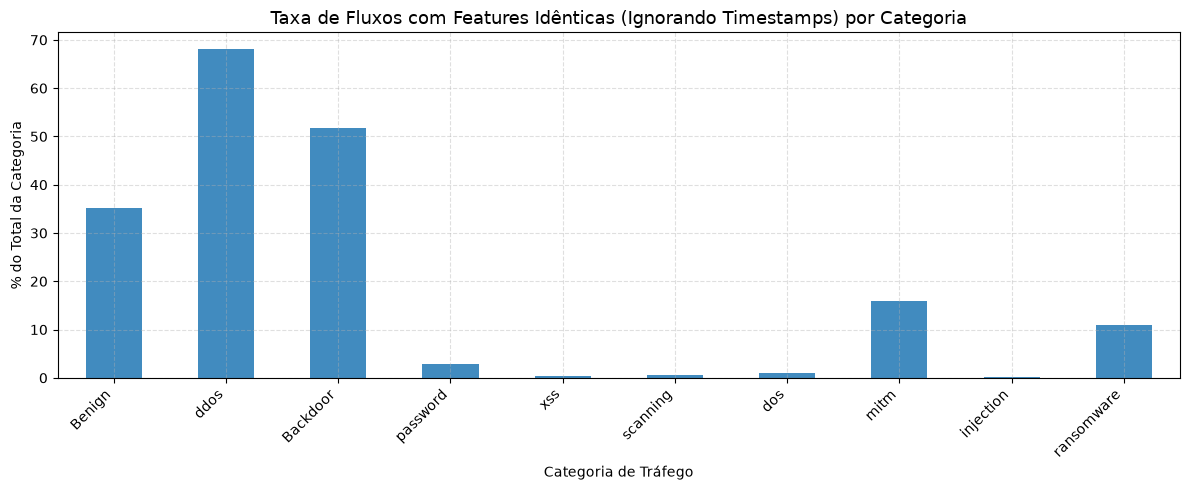

In [ ]:
# 1. Seleciona todas as colunas exceto os timestamps de início e fim
colunas_sem_timestamp = [
    c for c in dataset.columns
    if c not in ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'datetime']
]

# 2. Identifica duplicatas excedentes sem considerar o tempo
dups_sem_tempo_mask = dataset.duplicated(subset=colunas_sem_timestamp, keep='first')

# 3. Calcula a distribuição por categoria de ataque
dups_sem_tempo_por_ataque = dataset[dups_sem_tempo_mask]['Attack'].value_counts()
total_por_ataque = dataset['Attack'].value_counts()

df_dups_sem_tempo = pd.DataFrame({
    'Total_Fluxos': total_por_ataque,
    'Duplicatas_Sem_Tempo': dups_sem_tempo_por_ataque,
    'Taxa_%': (dups_sem_tempo_por_ataque / total_por_ataque * 100).round(2)
}).fillna(0).sort_values('Duplicatas_Sem_Tempo', ascending=False)

print(
    f"Total de duplicatas (sem timestamp): {dups_sem_tempo_mask.sum():,} "
    f"({dups_sem_tempo_mask.mean()*100:.2f}%)"
)
display(df_dups_sem_tempo)

# 4. Gráfico comparativo da taxa de repetição por ataque
plt.figure(figsize=(12, 5))
df_dups_sem_tempo['Taxa_%'].plot(kind='bar', color='#1f77b4', alpha=0.85)
plt.title(
    'Taxa de Fluxos com Features Idênticas Ignorando Timestamps por Categoria',
    fontsize=13,
)
plt.ylabel('% do Total da Categoria')
plt.xlabel('Categoria de Tráfego')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [3]:
colunas = dataset.columns
for col in colunas:
    not_nulls = dataset[col].count()
    print(f'{not_nulls}, {col}')

27520260, FLOW_START_MILLISECONDS
27520260, FLOW_END_MILLISECONDS
27520260, IPV4_SRC_ADDR
27520260, L4_SRC_PORT
27520260, IPV4_DST_ADDR
27520260, L4_DST_PORT
27520260, PROTOCOL
27520260, L7_PROTO
27520260, IN_BYTES
27520260, IN_PKTS
27520260, OUT_BYTES
27520260, OUT_PKTS
27520260, TCP_FLAGS
27520260, CLIENT_TCP_FLAGS
27520260, SERVER_TCP_FLAGS
27520260, FLOW_DURATION_MILLISECONDS
27520260, DURATION_IN
27520260, DURATION_OUT
27520260, MIN_TTL
27520260, MAX_TTL
27520260, LONGEST_FLOW_PKT
27520260, SHORTEST_FLOW_PKT
27520260, MIN_IP_PKT_LEN
27520260, MAX_IP_PKT_LEN
27520260, SRC_TO_DST_SECOND_BYTES
27520260, DST_TO_SRC_SECOND_BYTES
27520260, RETRANSMITTED_IN_BYTES
27520260, RETRANSMITTED_IN_PKTS
27520260, RETRANSMITTED_OUT_BYTES
27520260, RETRANSMITTED_OUT_PKTS
27520260, SRC_TO_DST_AVG_THROUGHPUT
27520260, DST_TO_SRC_AVG_THROUGHPUT
27520260, NUM_PKTS_UP_TO_128_BYTES
27520260, NUM_PKTS_128_TO_256_BYTES
27520260, NUM_PKTS_256_TO_512_BYTES
27520260, NUM_PKTS_512_TO_1024_BYTES
27520260, NUM_P

In [ ]:
print(dataset['Attack'].unique())
dataset['Attack'].value_counts(normalize=True)

In [ ]:
dataset['IPV4_DST_ADDR'].value_counts()

In [ ]:
dataset['IPV4_SRC_ADDR'].value_counts()

In [ ]:
ignore_cols = ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Attack']
num_cols = [c for c in dataset.columns if c not in ignore_cols]

corr_matrix = dataset[num_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(20, 16))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1.0,
    vmin=-1.0,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Coeficiente de Correlação de Pearson"}
)

plt.title(
    'Matriz de Correlação das Features NetFlow (NF-ToN-IoT-v3)', fontsize=16, pad=20
)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

--- Estatísticas Centrais por Grupo (Mediana e Intervalo Interquartil) ---


,IN_BYTES_median,IN_BYTES_<lambda_0>,IN_PKTS_median,IN_PKTS_<lambda_0>,FLOW_DURATION_MILLISECONDS_median,FLOW_DURATION_MILLISECONDS_<lambda_0>,SRC_TO_DST_AVG_THROUGHPUT_median,SRC_TO_DST_AVG_THROUGHPUT_<lambda_0>,LONGEST_FLOW_PKT_median,LONGEST_FLOW_PKT_<lambda_0>
Grupo,,,,,,,,,,
Benigno,52.0,27.0,1.0,0.0,1.0,0.0,384000.0,128000.0,52.0,27.0
Furtivo/Aplicação,346.0,350.0,5.0,3.0,301.0,1020.0,19020.5,133267.0,374.0,1440.0
Volumétrico,70.0,64.0,1.0,1.0,1.0,8.0,352000.0,274667.0,50.0,16.0


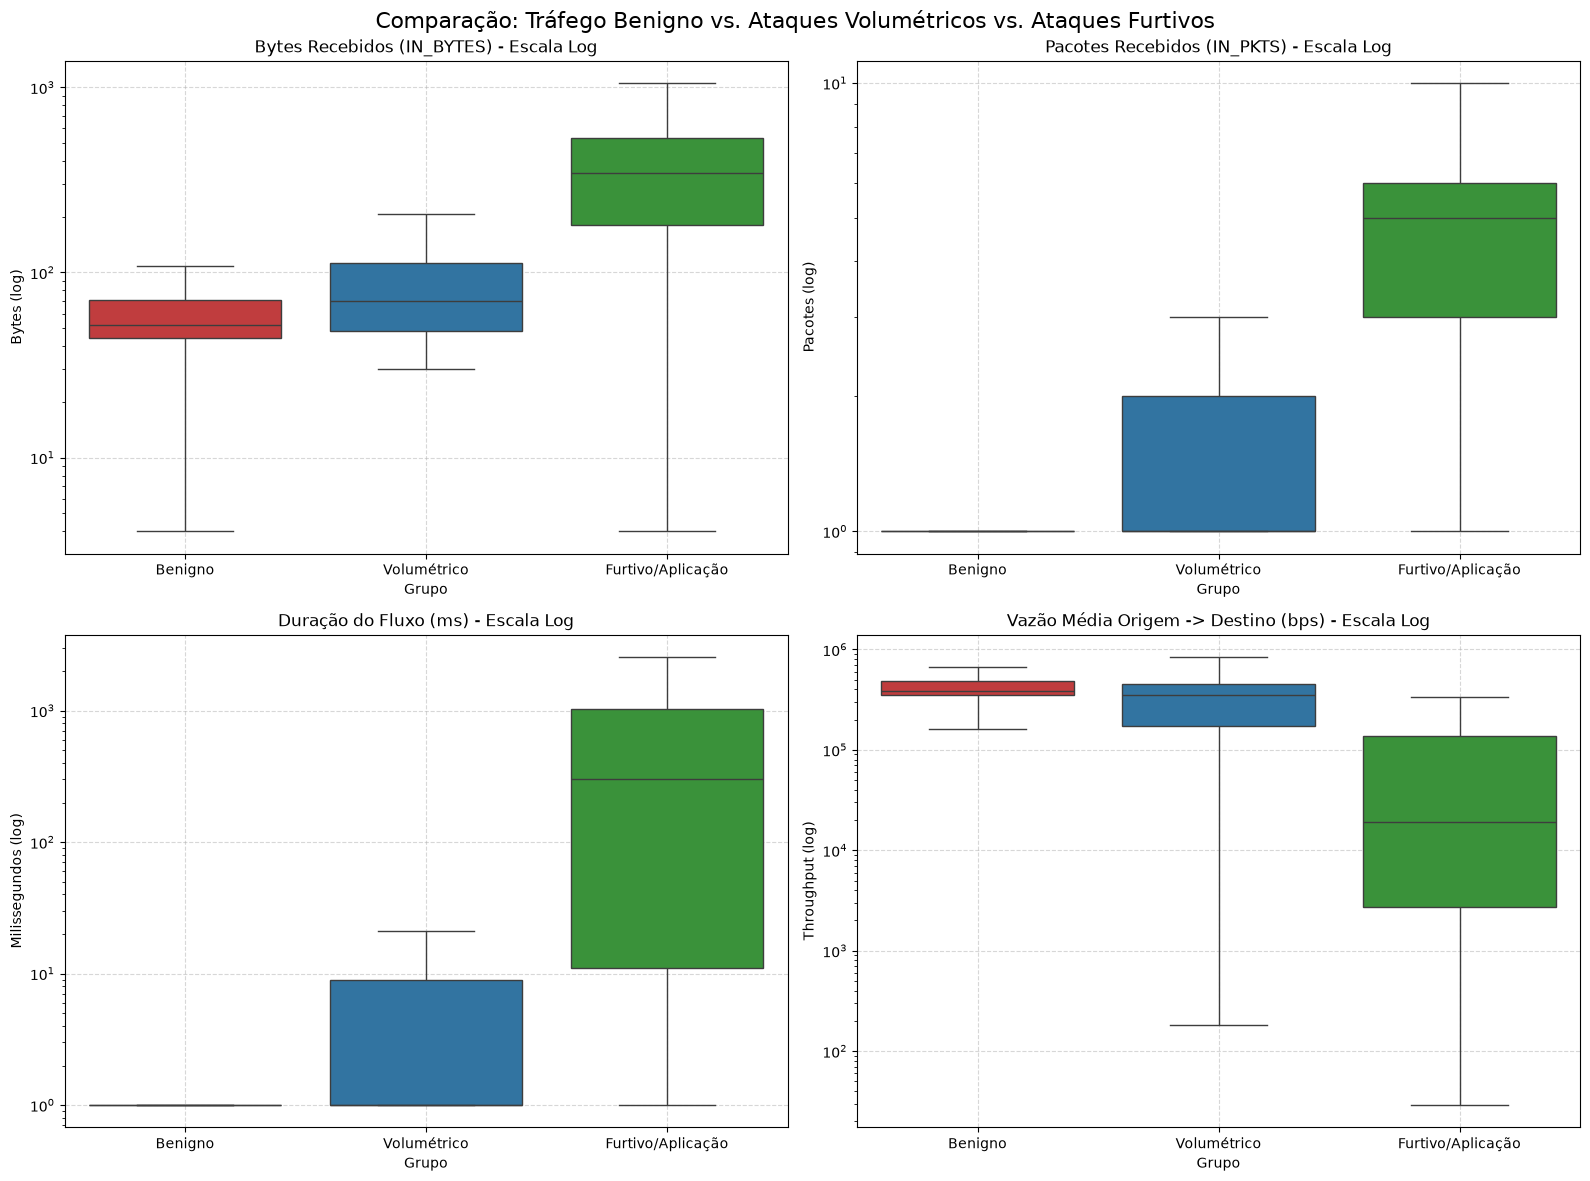

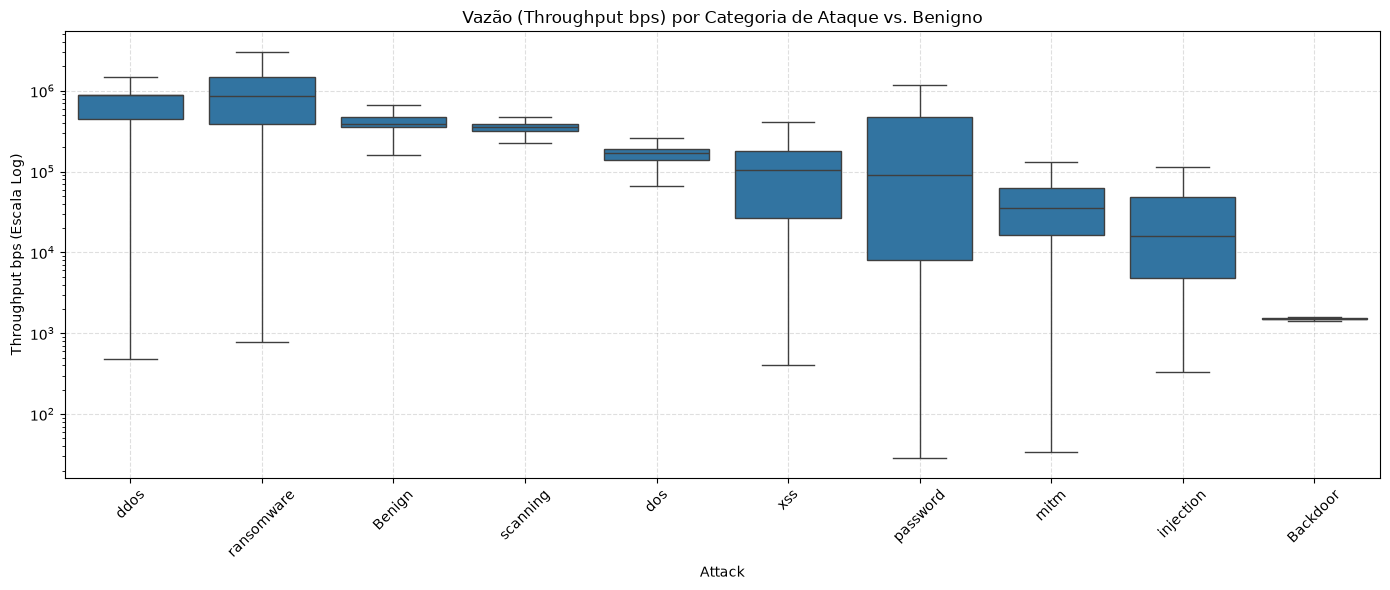

In [ ]:

df = dataset

# 1. Definir o agrupamento conceitual
grupos_ataque = {
    'Benign': 'Benigno',
    'ddos': 'Volumétrico',
    'dos': 'Volumétrico',
    'scanning': 'Volumétrico',
    'xss': 'Furtivo/Aplicação',
    'injection': 'Furtivo/Aplicação',
    'password': 'Furtivo/Aplicação',
    'Backdoor': 'Furtivo/Aplicação',
    'mitm': 'Furtivo/Aplicação',
    'ransomware': 'Furtivo/Aplicação'
}

# 2. Features de tráfego chave para contraste
features_analise = [
    'IN_BYTES',
    'IN_PKTS',
    'FLOW_DURATION_MILLISECONDS',
    'SRC_TO_DST_AVG_THROUGHPUT',
    'LONGEST_FLOW_PKT'
]

# 3. Amostragem representativa estratificada (compatível com Pandas 3.x)
sample_indices = [
    idx
    for _, group in df.groupby('Attack')
    for idx in group.sample(min(len(group), 30000), random_state=42).index
]
sample_df = df.loc[sample_indices].copy()

# Mapeia os grupos
sample_df['Grupo'] = sample_df['Attack'].map(grupos_ataque)

# ==============================================================================
# PARTE A: Tabela Comparativa de Estatísticas (Mediana e IQR)
# ==============================================================================
tabela_estatisticas = sample_df.groupby('Grupo')[features_analise].agg(
    ['median', lambda x: x.quantile(0.75) - x.quantile(0.25)]
)
tabela_estatisticas.columns = [
    f"{col}_{stat}" for col, stat in tabela_estatisticas.columns
]
print("--- Estatísticas Centrais por Grupo (Mediana e Intervalo Interquartil) ---")
display(tabela_estatisticas)

# ==============================================================================
# PARTE B: Visualização Boxplots Comparativos em Escala Log
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ordem_grupos = ['Benigno', 'Volumétrico', 'Furtivo/Aplicação']
cores = ['#2ca02c', '#d62728', '#1f77b4']

# 1. Bytes de Entrada (IN_BYTES)
sns.boxplot(
    data=sample_df, x='Grupo', y='IN_BYTES', order=ordem_grupos,
    hue='Grupo', palette=cores, legend=False, ax=axes[0, 0], showfliers=False
)
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Bytes Recebidos (IN_BYTES) - Escala Log')
axes[0, 0].set_ylabel('Bytes (log)')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# 2. Pacotes de Entrada (IN_PKTS)
sns.boxplot(
    data=sample_df, x='Grupo', y='IN_PKTS', order=ordem_grupos,
    hue='Grupo', palette=cores, legend=False, ax=axes[0, 1], showfliers=False
)
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Pacotes Recebidos (IN_PKTS) - Escala Log')
axes[0, 1].set_ylabel('Pacotes (log)')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# 3. Duração do Fluxo em Milissegundos
sns.boxplot(
    data=sample_df, x='Grupo', y='FLOW_DURATION_MILLISECONDS', order=ordem_grupos,
    hue='Grupo', palette=cores, legend=False, ax=axes[1, 0], showfliers=False
)
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Duração do Fluxo (ms) - Escala Log')
axes[1, 0].set_ylabel('Milissegundos (log)')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# 4. Throughput de Origem para Destino
sns.boxplot(
    data=sample_df, x='Grupo', y='SRC_TO_DST_AVG_THROUGHPUT', order=ordem_grupos,
    hue='Grupo', palette=cores, legend=False, ax=axes[1, 1], showfliers=False
)
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Vazão Média Origem -> Destino (bps) - Escala Log')
axes[1, 1].set_ylabel('Throughput (log)')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle(
    'Comparação: Tráfego Benigno vs. Ataques Volumétricos vs. Ataques Furtivos',
    fontsize=16,
)
plt.tight_layout()
plt.show()

# ==============================================================================
# PARTE C: Detalhamento por Categoria Específica de Ataque
# ==============================================================================
plt.figure(figsize=(14, 6))
order = (
    sample_df.groupby('Attack')['SRC_TO_DST_AVG_THROUGHPUT']
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=sample_df, x='Attack', y='SRC_TO_DST_AVG_THROUGHPUT', order=order,
    showfliers=False
)
plt.yscale('log')
plt.xticks(rotation=45)
plt.title('Vazão (Throughput bps) por Categoria de Ataque vs. Benigno')
plt.ylabel('Throughput bps (Escala Log)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
df = dataset

# 1. Definir o agrupamento conceitual
grupos_ataque = {
    'Benign': 'Benigno',
    'ddos': 'Volumétrico',
    'dos': 'Volumétrico',
    'scanning': 'Volumétrico',
    'xss': 'Furtivo/Aplicação',
    'injection': 'Furtivo/Aplicação',
    'password': 'Furtivo/Aplicação',
    'Backdoor': 'Furtivo/Aplicação',
    'mitm': 'Furtivo/Aplicação',
    'ransomware': 'Furtivo/Aplicação'
}

# 2. Features de tráfego chave para contraste
features_analise = [
    'IN_BYTES',
    'IN_PKTS',
    'FLOW_DURATION_MILLISECONDS',
    'SRC_TO_DST_AVG_THROUGHPUT',
    'LONGEST_FLOW_PKT'
]

# 3. Amostragem representativa estratificada (compatível com Pandas 3.x)
sample_indices = [
    idx
    for _, group in df.groupby('Attack')
    for idx in group.sample(min(len(group), 30000), random_state=42).index
]
sample_df = df.loc[sample_indices].copy()
sample_df['Grupo'] = sample_df['Attack'].map(grupos_ataque)


# Seleciona apenas as features numéricas reais de tráfego
colunas_ignorar = [
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Attack', 'Grupo', 'Label',
    'FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'datetime'
]
features_candidatas = [
    c for c in sample_df.columns
    if c not in colunas_ignorar and pd.api.types.is_numeric_dtype(sample_df[c])
]

# Remove eventuais NaNs ou Infs
X = sample_df[features_candidatas].replace([np.inf, -np.inf], np.nan).fillna(0)
y = sample_df['Grupo']

# Calcula o F-Score de cada feature em relação aos 3 grupos
f_scores, p_values = f_classif(X, y)

ranking_features = pd.DataFrame({
    'Feature': features_candidatas,
    'F_Score': f_scores,
    'p_value': p_values
}).sort_values('F_Score', ascending=False)

print(
    "--- Top 10 Features que Mais Diferenciam os Grupos "
    "(Critério Matemático: ANOVA F-Score) ---"
)
display(ranking_features.head(10))

--- Top 10 Features que Mais Diferenciam os Grupos (Critério Matemático: ANOVA F-Score) ---


,Feature,F_Score,p_value
1,L4_DST_PORT,68059.842531,0.0
10,SERVER_TCP_FLAGS,49736.426897,0.0
16,LONGEST_FLOW_PKT,39673.945953,0.0
19,MAX_IP_PKT_LEN,39673.945953,0.0
8,TCP_FLAGS,36870.025389,0.0
18,MIN_IP_PKT_LEN,33198.923027,0.0
0,L4_SRC_PORT,32946.017218,0.0
33,TCP_WIN_MAX_IN,26080.370525,0.0
14,MIN_TTL,20721.688193,0.0
15,MAX_TTL,20680.928766,0.0


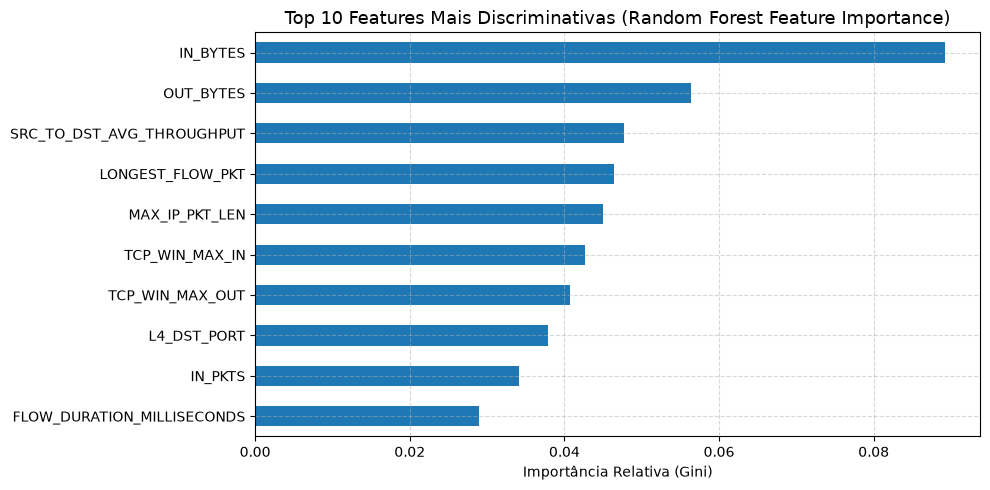

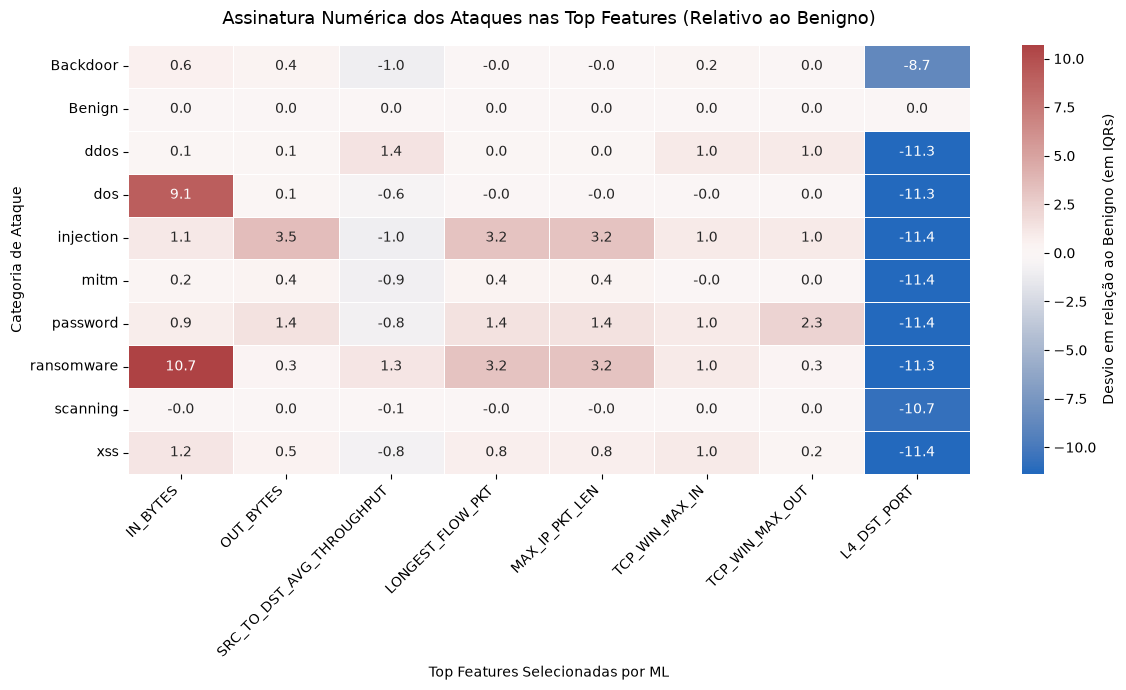

In [ ]:
# 1. Preparação das features numéricas (removendo identificadores e timestamps)
colunas_ignorar = [
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Attack', 'Grupo', 'Label',
    'FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'datetime'
]
features_ml = [
    c for c in sample_df.columns
    if c not in colunas_ignorar and pd.api.types.is_numeric_dtype(sample_df[c])
]

X = sample_df[features_ml].replace([np.inf, -np.inf], np.nan).fillna(0)
y = sample_df['Attack']

# 2. Random Forest para medir a importância não-linear das features
#    na separação dos ataques
rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X, y)

# Ranking de Importância
importancias = pd.Series(rf.feature_importances_, index=features_ml).sort_values(
    ascending=False
)
top_features = importancias.head(8).index.tolist()

# Visualização das Top Features por Random Forest
plt.figure(figsize=(10, 5))
importancias.head(10).plot(kind='barh', color='#1f77b4')
plt.gca().invert_yaxis()
plt.title(
    'Top 10 Features Mais Discriminativas (Random Forest Feature Importance)',
    fontsize=13,
)
plt.xlabel('Importância Relativa (Gini)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Heatmap de Assinatura por Ataque (Z-Score em relação à média geral)
# Mostra se cada ataque fica acima (+Z) ou abaixo (-Z) da média nas top features
medias_por_ataque = sample_df.groupby('Attack')[top_features].median()

# Padronização (Z-Score Robusto usando Mediana e IQR) para colocar todas
# na mesma escala visual
z_score_ataques = (medias_por_ataque - medias_por_ataque.loc['Benign']) / (
    sample_df[top_features].quantile(0.75)
    - sample_df[top_features].quantile(0.25)
    + 1e-6
)

plt.figure(figsize=(12, 7))
sns.heatmap(
    z_score_ataques,
    cmap='vlag',
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={'label': 'Desvio em relação ao Benigno (em IQRs)'}
)
plt.title(
    'Assinatura Numérica dos Ataques nas Top Features Relativo ao Benigno',
    fontsize=13,
    pad=15,
)
plt.ylabel('Categoria de Ataque')
plt.xlabel('Top Features Selecionadas por ML')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
#essa figura explica o motivo de dropar timestamp

df = dataset
# 1. Converte o timestamp para DateTime legível
df['datetime'] = pd.to_datetime(df['FLOW_START_MILLISECONDS'], unit='ms')

# 2. Timeline por Categoria (Scatter / Event Strip Plot)
# Mostra exatamente em quais janelas de tempo cada ataque foi executado
plt.figure(figsize=(14, 6))

# Fazemos uma amostragem se o dataframe for muito pesado para o scatter
sample_df = df.sample(min(100_000, len(df)), random_state=42)

for attack_type in sample_df['Attack'].unique():
    subset = sample_df[sample_df['Attack'] == attack_type]
    plt.scatter(
        subset['datetime'],
        subset['Attack'],
        alpha=0.3,
        s=10,
        label=attack_type
    )

plt.title('Linha do Tempo de Atividade por Categoria de Tráfego', fontsize=14)
plt.xlabel('Data / Hora da Captura')
plt.ylabel('Categoria')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()